# Real Madrid AI Transfer Intelligence
## Notebook 04 — Position-Aware Player Performance Rating

**Objective:** build a transparent, explainable player rating from the cleaned player-season dataset. The score is calculated within broad position groups and within each season, so forwards are not directly ranked against goalkeepers and players are compared against peers from the same season.

**Input:** `data/processed/real_madrid_player_season_clean.csv` from Notebook 02.

**Important limitations**
- This is a first version of a descriptive performance score, not a prediction of future ability or transfer success.
- Available metrics depend on what Notebook 01 successfully collected. The notebook prints the metrics it actually finds.
- Missing values are not treated as zero. Weights are re-normalized over available metrics.
- Small samples are flagged. A minimum-minutes filter is used for the main leaderboard, while all players remain in the exported table.
- Do not interpret a score as a causal measure of player quality.


## 1. Load data and inspect available metrics

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "data").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_DIR = PROJECT_ROOT / "data" / "processed"
REPORTS_DIR = PROJECT_ROOT / "reports"
FIGURES_DIR = PROJECT_ROOT / "figures"
REPORTS_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

INPUT_PATH = DATA_DIR / "real_madrid_player_season_clean.csv"
if not INPUT_PATH.exists():
    raise FileNotFoundError(f"Missing {INPUT_PATH}. Run Notebook 02 first.")

df = pd.read_csv(INPUT_PATH)
print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())
display(df.head())


,league,season,team,player_name,nation,pos,age,born,playing_time_mp,playing_time_starts,...,retrieved_at_utc,scope,competition,position,minutes,starts,goals,player_id,club,goals_per_90
0,ESP-La Liga,2324,Real Madrid,Andriy Lunin,UKR,GK,24,1999,21,21,...,2026-11-05T08:28:00.400181+00:00,La Liga,ESP-La Liga,GK,1890.0,21,0,andriy_lunin,Real Madrid,0.000000
1,ESP-La Liga,2324,Real Madrid,Antonio Rüdiger,GER,DF,30,1993,33,30,...,2026-11-05T08:28:00.400181+00:00,La Liga,ESP-La Liga,DF,2709.0,30,1,antonio_rudiger,Real Madrid,0.033223
2,ESP-La Liga,2324,Real Madrid,Arda Güler,TUR,"MF,FW",18,2005,10,4,...,2026-11-05T08:28:00.400181+00:00,La Liga,ESP-La Liga,"MF,FW",377.0,4,6,arda_guler,Real Madrid,1.432361
3,ESP-La Liga,2324,Real Madrid,Aurélien Tchouaméni,FRA,"MF,DF",23,2000,27,22,...,2026-11-05T08:28:00.400181+00:00,La Liga,ESP-La Liga,"MF,DF",1987.0,22,3,aurelien_tchouameni,Real Madrid,0.135883
4,ESP-La Liga,2324,Real Madrid,Brahim Díaz,MAR,"MF,FW",23,1999,31,18,...,2026-11-05T08:28:00.400181+00:00,La Liga,ESP-La Liga,"MF,FW",1545.0,18,8,brahim_diaz,Real Madrid,0.466019


## 2. Standardize core fields and positions

In [2]:
def first_existing(options):
    return next((c for c in options if c in df.columns), None)

field_map = {
    "player_name": first_existing(["player_name", "player"]),
    "season": first_existing(["season"]),
    "position": first_existing(["position", "pos"]),
    "minutes": first_existing(["minutes", "min", "playing_time_min"]),
}
display(pd.DataFrame([{"field": k, "source_column": v} for k, v in field_map.items()]))

if field_map["player_name"] is None or field_map["season"] is None:
    raise ValueError(f"Missing player_name or season. Available columns: {df.columns.tolist()}")

for target, source in field_map.items():
    if source and target not in df.columns:
        df[target] = df[source]

if field_map["position"] is None:
    raise ValueError("Position column is required for a position-aware score. Check Notebook 01 data collection.")

df["minutes"] = pd.to_numeric(df["minutes"], errors="coerce") if "minutes" in df.columns else np.nan

def map_position(value):
    if pd.isna(value):
        return "Unknown"
    # FBref position strings can contain combinations such as FW,MF or MF,DF.
    tokens = [x.strip().upper() for x in re.split(r"[,;/ ]+", str(value)) if x.strip()]
    token_set = set(tokens)
    if "GK" in token_set:
        return "GK"
    if "FW" in token_set:
        return "FW"
    if "MF" in token_set:
        return "MF"
    if "DF" in token_set:
        return "DF"
    return "Unknown"

df["position_group"] = df["position"].map(map_position)
display(df[["player_name", "season", "position", "position_group", "minutes"]].head(15))


,player_name,season,position,position_group,minutes
0,Andriy Lunin,2324,GK,GK,1890.0
1,Antonio Rüdiger,2324,DF,DF,2709.0
2,Arda Güler,2324,"MF,FW",FW,377.0
3,Aurélien Tchouaméni,2324,"MF,DF",MF,1987.0
4,Brahim Díaz,2324,"MF,FW",FW,1545.0
5,Dani Carvajal,2324,DF,DF,2171.0
6,Dani Ceballos,2324,MF,MF,598.0
7,David Alaba,2324,DF,DF,1154.0
8,Eduardo Camavinga,2324,MF,MF,1817.0
9,Federico Valverde,2324,MF,MF,2904.0


## 3. Identify available performance metrics

In [3]:
# Candidate metrics and their direction. All listed metrics are 'higher is better'
# for this first descriptive score. Do not add defensive error metrics without reversing direction.
METRIC_CANDIDATES = {
    "goals_per_90": ["goals_per_90"],
    "assists_per_90": ["assists_per_90"],
    "goal_contributions_per_90": ["goal_contributions_per_90"],
    "xg_per_90": ["xg_per_90", "xg_per90", "expected_goals_per_90"],
    "xa_per_90": ["xa_per_90", "xa_per90", "expected_assists_per_90"],
    "shots_per_90": ["shots_per_90", "shots_per90"],
    "key_passes_per_90": ["key_passes_per_90", "key_passes_per90"],
    "progressive_passes_per_90": ["progressive_passes_per_90", "progressive_passes_per90"],
    "progressive_carries_per_90": ["progressive_carries_per_90", "progressive_carries_per90"],
    "tackles_interceptions_per_90": ["tackles_interceptions_per_90", "tackles_plus_interceptions_per_90"],
}

available_metrics = {}
for canonical, options in METRIC_CANDIDATES.items():
    source = next((c for c in options if c in df.columns), None)
    if source:
        df[canonical] = pd.to_numeric(df[source], errors="coerce")
        available_metrics[canonical] = source

print("Metrics found:")
display(pd.DataFrame([{"metric": k, "source_column": v} for k, v in available_metrics.items()]))

if not available_metrics:
    raise ValueError(
        "No supported performance metrics found. Check that Notebook 02 preserved goals_per_90 "
        "and assists_per_90, or update METRIC_CANDIDATES to match your CSV columns."
    )


,metric,source_column
0,goals_per_90,goals_per_90


## 4. Define transparent position-specific weights

In [4]:
# Initial weights are a project methodology choice, not universal football truth.
# Weights are re-normalized over the metrics available in this dataset.
POSITION_WEIGHTS = {
    "FW": {
        "goals_per_90": 0.35, "assists_per_90": 0.20,
        "goal_contributions_per_90": 0.25, "xg_per_90": 0.10,
        "xa_per_90": 0.10
    },
    "MF": {
        "goals_per_90": 0.15, "assists_per_90": 0.25,
        "goal_contributions_per_90": 0.20, "xg_per_90": 0.10,
        "xa_per_90": 0.15, "key_passes_per_90": 0.10,
        "progressive_passes_per_90": 0.05
    },
    "DF": {
        "assists_per_90": 0.15, "goal_contributions_per_90": 0.10,
        "progressive_passes_per_90": 0.25, "progressive_carries_per_90": 0.15,
        "tackles_interceptions_per_90": 0.25, "key_passes_per_90": 0.10
    },
    "GK": {
        # Goalkeeper-specific metrics should be added when sourced and validated.
    }
}

print("Weights are position-specific. If only goals/assists exist, this first score is attack-output-heavy.")


Weights are position-specific. If only goals/assists exist, this first score is attack-output-heavy.


## 5. Calculate percentile scores within season and position

In [5]:
# Percentile ranks reduce scale differences between metrics.
# A score is calculated only when at least one configured metric is present for that position.
score_rows = []

for (season, position), group in df.groupby(["season", "position_group"], dropna=False):
    configured = POSITION_WEIGHTS.get(position, {})
    metric_weights = {
        metric: weight for metric, weight in configured.items()
        if metric in available_metrics and metric in group.columns
    }

    if not metric_weights:
        continue

    normalized_weights = {
        metric: weight / sum(metric_weights.values())
        for metric, weight in metric_weights.items()
    }

    percentile_columns = {}
    for metric in normalized_weights:
        percentile_columns[metric] = group[metric].rank(pct=True, method="average") * 100

    percentile_df = pd.DataFrame(percentile_columns, index=group.index)
    weighted_values = pd.DataFrame({
        metric: percentile_df[metric] * weight
        for metric, weight in normalized_weights.items()
    })

    # Missing metric values do not become zero; calculate a weighted average
    # over the metrics observed for each player.
    numerator = weighted_values.sum(axis=1, min_count=1)
    denominator = pd.DataFrame({
        metric: percentile_df[metric].notna().astype(float) * weight
        for metric, weight in normalized_weights.items()
    }).sum(axis=1)

    score = numerator / denominator.replace(0, np.nan)

    for idx in group.index:
        score_rows.append({
            "index": idx,
            "performance_score": score.loc[idx],
            "metrics_used": int(percentile_df.loc[idx].notna().sum()),
            "position_metrics_available": len(normalized_weights),
            "position_group": position,
            "season": season
        })

score_df = pd.DataFrame(score_rows)
if score_df.empty:
    raise ValueError("No scores were calculated. Inspect position labels and available metrics.")

df = df.join(score_df.set_index("index")[["performance_score", "metrics_used", "position_metrics_available"]], how="left")
df["performance_score"] = df["performance_score"].round(2)

print("Scored rows:", int(df["performance_score"].notna().sum()), "of", len(df))
display(df[["player_name", "season", "position_group", "minutes", "performance_score", "metrics_used"]].head(20))


,player_name,season,position_group,minutes,performance_score,metrics_used
0,Andriy Lunin,2324,GK,1890.0,NaN,NaN
1,Antonio Rüdiger,2324,DF,2709.0,NaN,NaN
2,Arda Güler,2324,FW,377.0,100.00,1.0
3,Aurélien Tchouaméni,2324,MF,1987.0,100.00,1.0
4,Brahim Díaz,2324,FW,1545.0,50.00,1.0
5,Dani Carvajal,2324,DF,2171.0,NaN,NaN
6,Dani Ceballos,2324,MF,598.0,31.25,1.0
7,David Alaba,2324,DF,1154.0,NaN,NaN
8,Eduardo Camavinga,2324,MF,1817.0,31.25,1.0
9,Federico Valverde,2324,MF,2904.0,75.00,1.0


## 6. Add sample-size confidence flags

In [6]:
MIN_MINUTES_FOR_MAIN_RANKING = 450

df["sample_flag"] = np.select(
    [
        df["minutes"].isna(),
        df["minutes"] < 180,
        df["minutes"] < MIN_MINUTES_FOR_MAIN_RANKING
    ],
    [
        "Minutes missing",
        "Very small sample (<180)",
        "Limited sample (<450)"
    ],
    default="Sufficient sample (>=450)"
)

# Main ranking: retain only players with at least 450 minutes and a calculated score.
leaderboard = df[
    df["performance_score"].notna()
    & df["minutes"].ge(MIN_MINUTES_FOR_MAIN_RANKING)
].copy()

leaderboard = leaderboard.sort_values(
    ["season", "position_group", "performance_score"],
    ascending=[True, True, False]
)

display(leaderboard[[
    "season", "player_name", "position_group", "minutes",
    "performance_score", "metrics_used", "sample_flag"
]].head(30))


,season,player_name,position_group,minutes,performance_score,metrics_used,sample_flag
14,2324,Jude Bellingham,FW,2315.0,87.50,1.0,Sufficient sample (>=450)
24,2324,Vinicius Júnior,FW,1864.0,75.00,1.0,Sufficient sample (>=450)
13,2324,Joselu,FW,1687.0,62.50,1.0,Sufficient sample (>=450)
4,2324,Brahim Díaz,FW,1545.0,50.00,1.0,Sufficient sample (>=450)
21,2324,Rodrygo,FW,2380.0,37.50,1.0,Sufficient sample (>=450)
3,2324,Aurélien Tchouaméni,MF,1987.0,100.00,1.0,Sufficient sample (>=450)
17,2324,Luka Modrić,MF,1688.0,87.50,1.0,Sufficient sample (>=450)
9,2324,Federico Valverde,MF,2904.0,75.00,1.0,Sufficient sample (>=450)
23,2324,Toni Kroos,MF,2124.0,62.50,1.0,Sufficient sample (>=450)
6,2324,Dani Ceballos,MF,598.0,31.25,1.0,Sufficient sample (>=450)


## 7. Visualize the position-aware leaderboard

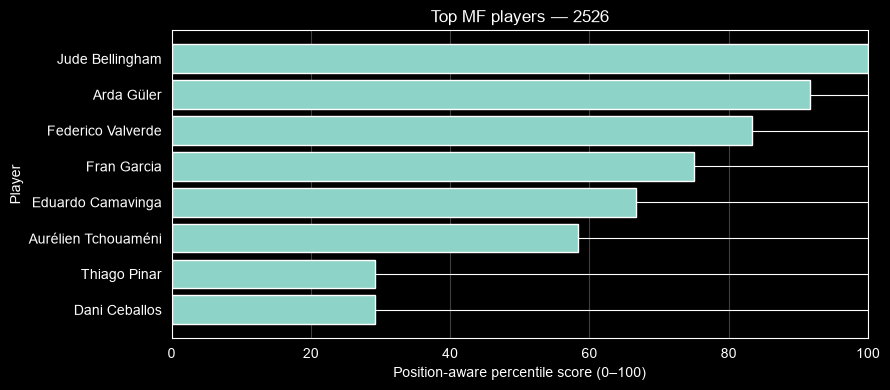

In [7]:
if not leaderboard.empty:
    latest_season = sorted(leaderboard["season"].dropna().astype(str).unique())[-1]
    latest = leaderboard[leaderboard["season"].astype(str) == latest_season].copy()

    # Top 10 within each position group, not one cross-position ranking.
    top_by_position = (
        latest.sort_values("performance_score", ascending=False)
        .groupby("position_group", group_keys=False)
        .head(10)
    )

    for position, group in top_by_position.groupby("position_group"):
        if group.empty:
            continue
        plot_data = group.sort_values("performance_score", ascending=True)
        fig, ax = plt.subplots(figsize=(9, max(4, len(plot_data) * 0.35)))
        ax.barh(plot_data["player_name"], plot_data["performance_score"])
        ax.set_title(f"Top {position} players — {latest_season}")
        ax.set_xlabel("Position-aware percentile score (0–100)")
        ax.set_ylabel("Player")
        ax.set_xlim(0, 100)
        ax.grid(axis="x", alpha=0.25)
        plt.tight_layout()
        plt.savefig(FIGURES_DIR / f"rating_top_{position.lower()}_{latest_season.replace('/', '-')}.png", dpi=160)
        plt.show()
else:
    print("No players passed the minutes threshold. Lower the threshold only with a documented reason.")


## 8. Explain score components for one season

In [8]:
# This table makes the score auditable. It shows raw metrics and sample size.
audit_columns = [
    c for c in [
        "season", "player_name", "position", "position_group", "minutes",
        "goals_per_90", "assists_per_90", "goal_contributions_per_90",
        "xg_per_90", "xa_per_90", "key_passes_per_90",
        "progressive_passes_per_90", "progressive_carries_per_90",
        "tackles_interceptions_per_90", "performance_score", "metrics_used", "sample_flag"
    ] if c in df.columns
]
display(df[audit_columns].sort_values(["season", "performance_score"], ascending=[True, False]).head(50))


,season,player_name,position,position_group,minutes,goals_per_90,performance_score,metrics_used,sample_flag
2,2324,Arda Güler,"MF,FW",FW,377.0,1.432361,100.00,1.0,Limited sample (<450)
3,2324,Aurélien Tchouaméni,"MF,DF",MF,1987.0,0.135883,100.00,1.0,Sufficient sample (>=450)
14,2324,Jude Bellingham,"MF,FW",FW,2315.0,0.738661,87.50,1.0,Sufficient sample (>=450)
17,2324,Luka Modrić,MF,MF,1688.0,0.106635,87.50,1.0,Sufficient sample (>=450)
9,2324,Federico Valverde,MF,MF,2904.0,0.061983,75.00,1.0,Sufficient sample (>=450)
24,2324,Vinicius Júnior,FW,FW,1864.0,0.724249,75.00,1.0,Sufficient sample (>=450)
13,2324,Joselu,FW,FW,1687.0,0.533491,62.50,1.0,Sufficient sample (>=450)
23,2324,Toni Kroos,MF,MF,2124.0,0.042373,62.50,1.0,Sufficient sample (>=450)
4,2324,Brahim Díaz,"MF,FW",FW,1545.0,0.466019,50.00,1.0,Sufficient sample (>=450)
21,2324,Rodrygo,FW,FW,2380.0,0.378151,37.50,1.0,Sufficient sample (>=450)


## 9. Export rating results and methodology

In [9]:
rating_path = DATA_DIR / "real_madrid_player_ratings.csv"
leaderboard_path = REPORTS_DIR / "player_rating_leaderboard.csv"
methodology_path = REPORTS_DIR / "player_rating_methodology.json"

df.to_csv(rating_path, index=False)
leaderboard.to_csv(leaderboard_path, index=False)

methodology = {
    "score_name": "Position-aware Player Performance Score v1",
    "scale": "0-100 percentile-based composite",
    "comparison_group": "same season and broad position group",
    "minimum_minutes_for_main_leaderboard": MIN_MINUTES_FOR_MAIN_RANKING,
    "weights": POSITION_WEIGHTS,
    "metrics_found_in_dataset": available_metrics,
    "missing_metric_policy": "Do not impute missing metrics; re-normalize weights across available metrics per position.",
    "small_sample_policy": "Flag all players under 450 minutes; main leaderboard requires at least 450 minutes.",
    "limitations": [
        "This is a descriptive score, not a forecast of future performance.",
        "Score depends on the metrics available in the source extract.",
        "Percentile scores depend on the observed players in each season-position group.",
        "Goalkeepers are not scored until goalkeeper-specific metrics are added.",
        "A minimum-minute threshold reduces but does not eliminate sample-size bias."
    ]
}
methodology_path.write_text(__import__("json").dumps(methodology, indent=2, ensure_ascii=False), encoding="utf-8")

print("Saved rating dataset:", rating_path)
print("Saved leaderboard:", leaderboard_path)
print("Saved methodology:", methodology_path)


Saved rating dataset: C:\Users\1alma\DataspellProjects\real-madrid-ai\data\processed\real_madrid_player_ratings.csv
Saved leaderboard: C:\Users\1alma\DataspellProjects\real-madrid-ai\reports\player_rating_leaderboard.csv
Saved methodology: C:\Users\1alma\DataspellProjects\real-madrid-ai\reports\player_rating_methodology.json
